# Исследовательский анализ данных — Набор данных об играх Steam

## 1. Введение

В данном ноутбуке представлен исследовательский анализ данных (EDA) набора данных об играх Steam, полученного с платформы Kaggle.

Набор данных содержит информацию об играх Steam, включая даты выпуска, цены, предполагаемое количество владельцев, активность игроков, жанры, разработчиков и другие метаданные.

### Цели исследования

- Изучить структуру набора данных и типы данных.
- Оценить полноту и согласованность данных.
- Выявить дубликаты, аномалии и выбросы.
- Исследовать распределения числовых и категориальных переменных.
- Изучить взаимосвязи между выбранными переменными.
- Оценить общее качество и ограничения набора данных.

## 2. Библиотеки и загрузка данных

Импорт необходимых библиотек и загрузка обработанного набора данных в формате Parquet.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# Locate and load the dataset

candidates = [
    Path("datasets/games.parquet"),
    Path("../datasets/games.parquet")
]

DATA_PATH = next(
    (path for path in candidates if path.exists()),
    None
)

if DATA_PATH is None:
    raise FileNotFoundError("games.parquet was not found.")

df = pd.read_parquet(DATA_PATH)

print(f"Dataset loaded successfully: {DATA_PATH}")

Dataset loaded successfully: ../datasets/games.parquet


In [3]:
print("Dataset dimensions:", df.shape)

display(df.head(10))

Dataset dimensions: (125855, 40)


,AppID,Name,Release date,Estimated owners,Peak CCU,Required age,Price,Discount,DLC count,About the game,Supported languages,Full audio languages,Reviews,Header image,Website,Support url,Support email,Windows,Mac,Linux,Metacritic score,Metacritic url,User score,Positive,Negative,Score rank,Achievements,Recommendations,Notes,Average playtime forever,Average playtime two weeks,Median playtime forever,Median playtime two weeks,Developers,Publishers,Categories,Genres,Tags,Screenshots,Movies
0,2539430,Black Dragon Mage Playtest,2023-08-01,0 - 0,0,0,0.0,0,0,<NA>,[],[],<NA>,https://shared.akamai.steamstatic.com/store_it...,<NA>,<NA>,<NA>,True,False,False,0,<NA>,0,0,0,<NA>,0,0,<NA>,0,0,0,0,<NA>,<NA>,<NA>,<NA>,<NA>,https://shared.akamai.steamstatic.com/store_it...,NaN
1,496350,Supipara - Chapter 1 Spring Has Come!,2016-07-29,0 - 20000,0,0,5.24,65,0,"Springtime, April: when the cherry trees come ...",['English'],[],<NA>,https://shared.akamai.steamstatic.com/store_it...,http://mangagamer.org/supipara,http://mangagamer.com,support@mangagamer.com,True,False,False,0,<NA>,0,252,3,<NA>,0,231,<NA>,8,0,8,0,minori,MangaGamer,"Single-player,Steam Trading Cards,Steam Cloud,...",Adventure,"Adventure,Visual Novel,Anime,Cute",https://shared.akamai.steamstatic.com/store_it...,NaN
2,1034400,Mystery Solitaire The Black Raven,2019-05-06,0 - 20000,0,0,4.99,0,0,"Immerse yourself in the most beloved, mystical...","['English', 'French', 'German', 'Russian']",[],<NA>,https://shared.akamai.steamstatic.com/store_it...,https://www.facebook.com/8FloorGames/,https://www.facebook.com/8FloorGames,support@8floor.net,True,True,False,0,<NA>,0,21,3,<NA>,0,0,<NA>,0,0,0,0,Somer Games,8floor,"Single-player,Family Sharing",Casual,"Casual,Card Game,Solitaire,Puzzle,Hidden Objec...",https://shared.akamai.steamstatic.com/store_it...,NaN
3,3292190,버튜버 파라노이아 - Vtuber Paranoia,2024-10-31,0 - 20000,1,0,8.99,0,1,"synopsis 'Hello, I'm Hiyoro, a new YouTuber!' ...",['Korean'],['Korean'],<NA>,https://shared.akamai.steamstatic.com/store_it...,<NA>,<NA>,yujingamesc@gmail.com,True,False,False,0,<NA>,0,0,0,<NA>,19,0,The game includes the following elements. 1. G...,0,0,0,0,유진게임즈,유진게임즈,"Single-player,Steam Achievements,Family Sharing","Casual,Indie,Simulation",<NA>,https://shared.akamai.steamstatic.com/store_it...,NaN
4,3631080,Maze Quest VR,2025-04-24,0 - 20000,0,0,4.99,0,0,Its not just a Maze; its a Quest! Enter the ca...,['English'],['English'],<NA>,https://shared.akamai.steamstatic.com/store_it...,https://www.realityexpanded.com/books-games,https://www.realityexpanded.com,support@realityexpanded.com,True,False,False,0,<NA>,0,0,0,<NA>,0,0,<NA>,0,0,0,0,Reality Expanded LLC,Reality Expanded LLC,"Single-player,VR Only,Steam Leaderboards,Famil...","Action,Early Access",<NA>,https://shared.akamai.steamstatic.com/store_it...,NaN
5,1654170,Agony VR,2023-04-05,0 - 20000,0,0,13.99,0,0,A JOURNEY THROUGH HELL! Explore the most terri...,"['English', 'French', 'Italian', 'German', 'Sp...","['English', 'Turkish']",<NA>,https://shared.akamai.steamstatic.com/store_it...,<NA>,https://www.ignibit.com/,office@ignibit.com,True,False,False,0,<NA>,0,0,0,<NA>,0,0,The trailer and the screenshots may contain co...,0,0,0,0,Ignibit,"Ignibit,Madmind Studio","Single-player,Tracked Controller Support,VR On...","Action,Adventure",<NA>,https://shared.akamai.steamstatic.com/store_it...,NaN
6,1934300,Armored Brigade II,2025-04-08,0 - 20000,8,0,35.99,10,1,Building on the success of its acclaimed prede...,['English'],[],<NA>,https://shared.akamai.steamstatic.com/store_it...,<NA>,<NA>,support@slitherine.co.uk,True,False,False,0,<NA>,0,117,13,<NA>,0,107,<NA>,675,0,1253,0,Veitikka Studios,Matrix Games,"Single-player,Steam Workshop,Steam Cloud,Famil...","Simulation,Strategy","Simulation,Strategy,RTS,Wargame,Grand Strategy...",https://shared.akamai.steamstatic.com/store_it...,NaN
7,700340,Galacatraz: Eject Equip Escape,2018-02-01,0 - 20000,0,0,0.99,0,0,"Years ago, Ricardo Luger was in the wrong plac...",['English'],['English'],

## 3. Структура набора данных

В этом разделе рассматриваются размер набора данных, названия столбцов, типы данных и объём используемой памяти для понимания его общей структуры.

In [4]:
# Display column names and data types

structure = pd.DataFrame({
    "Column": df.columns,
    "Data type": df.dtypes.astype(str).values,
    "Non-null values": df.notna().sum().values,
    "Missing values": df.isna().sum().values
})

display(structure)

,Column,Data type,Non-null values,Missing values
0,AppID,Int64,125855,0
1,Name,string,125854,1
2,Release date,datetime64[us],125855,0
3,Estimated owners,string,125855,0
4,Peak CCU,Int64,125855,0
5,Required age,Int64,125855,0
6,Price,Float64,125855,0
7,Discount,Int64,125855,0
8,DLC count,Int64,125855,0
9,About the game,string,117393,8462


In [5]:
# General information about the dataset

print("Number of records:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nMemory usage:")
print(f"{df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

print("\nData types distribution:")
display(df.dtypes.value_counts().rename("Number of columns"))

Number of records: 125855
Number of columns: 40

Memory usage:
404.85 MB

Data types distribution:


string            18
Int64             16
boolean            3
datetime64[us]     1
Float64            1
float64            1
Name: Number of columns, dtype: int64

In [6]:
# Check for duplicate records and duplicate AppIDs

print("Duplicate rows:", df.duplicated().sum())
print("Duplicate AppIDs:", df["AppID"].duplicated().sum())
print("Unique AppIDs:", df["AppID"].nunique())

Duplicate rows: 0
Duplicate AppIDs: 0
Unique AppIDs: 125855


## 4. Анализ пропущенных значений

Пропущенные значения могут влиять на надёжность и полноту набора данных.

Мы анализируем количество и процент пропущенных значений в каждом столбце, чтобы выявить поля с неполной информацией.

In [7]:
missing = pd.DataFrame({
    "Missing values": df.isna().sum(),
    "Missing (%)": df.isna().mean() * 100
})

missing = missing.sort_values(
    "Missing (%)",
    ascending=False
)

display(missing[missing["Missing values"] > 0].round(2))

,Missing values,Missing (%)
Movies,125855,100.00
Score rank,125815,99.97
Metacritic url,121597,96.62
Reviews,113674,90.32
Notes,102545,81.48
Website,75335,59.86
Support url,70560,56.06
Tags,42502,33.77
Support email,22630,17.98
Categories,8966,7.12


### 4.1 Анализ пропущенных значений — Результаты

Анализ пропущенных значений выявляет значительные различия в полноте данных между столбцами.

Столбец `Movies` содержит 100% пропущенных значений, в то время как `Score rank`, `Metacritic url`, `Reviews` и `Notes` также имеют очень высокую долю пропущенных данных.

В дополнительных полях метаданных, таких как `Website` и `Support url`, пропущенные значения встречаются более чем в половине записей. Это может отражать отсутствие доступной информации, а не ошибки при сборе данных.

В отличие от них, важные описательные поля, такие как `Name` и `Header image`, содержат очень мало пропущенных значений.

**Вывод:** Набор данных характеризуется неравномерной полнотой информации. Некоторые столбцы содержат много полезной информации, в то время как другие имеют ограниченную аналитическую ценность из-за отсутствия данных. Эти ограничения необходимо учитывать при проведении последующего анализа.

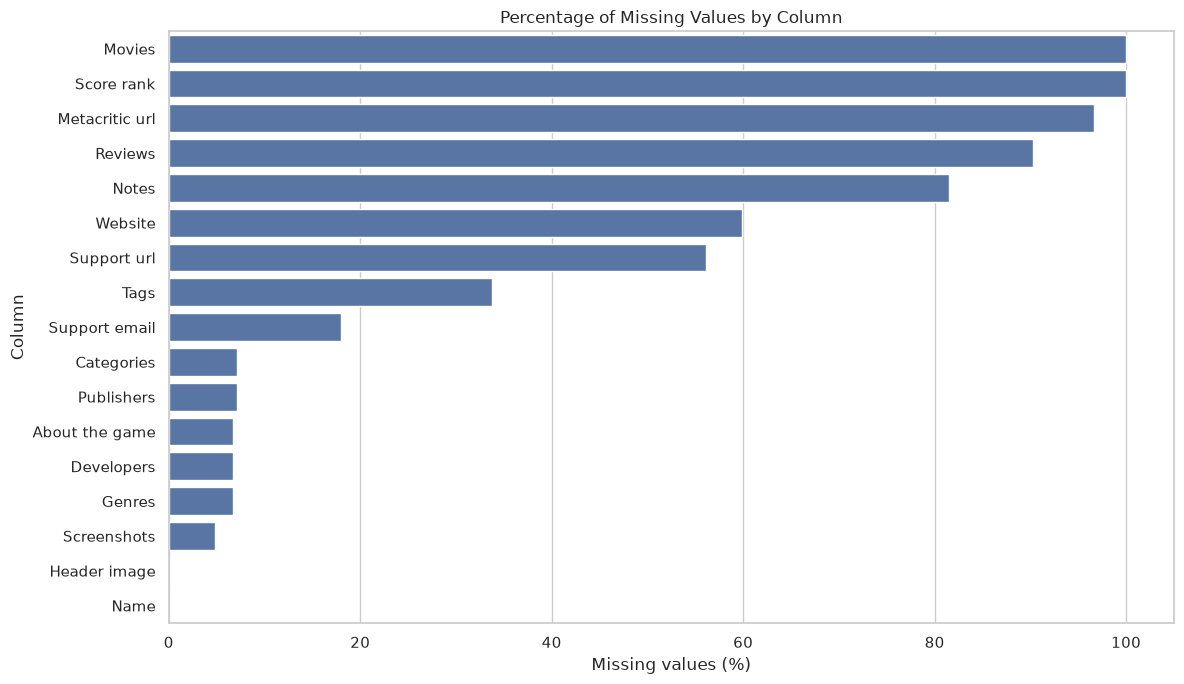

In [8]:
missing_data = missing[missing["Missing (%)"] > 0]

plt.figure(figsize=(12, 7))

sns.barplot(
    data=missing_data.reset_index(),
    x="Missing (%)",
    y="index"
)

plt.title("Percentage of Missing Values by Column")
plt.xlabel("Missing values (%)")
plt.ylabel("Column")
plt.tight_layout()
plt.show()

In [9]:
# Examine zero values in numerical columns

numeric_cols = df.select_dtypes(include="number").columns

zero_analysis = pd.DataFrame({
    "Zero count": (df[numeric_cols] == 0).sum(),
    "Zero percentage": (
        (df[numeric_cols] == 0).mean() * 100
    )
})

display(
    zero_analysis.sort_values(
        "Zero percentage",
        ascending=False
    ).round(2)
)

,Zero count,Zero percentage
User score,125815,99.97
Required age,124567,98.98
Average playtime two weeks,121907,96.86
Median playtime two weeks,121907,96.86
Metacritic score,121597,96.62
DLC count,107823,85.67
Peak CCU,106175,84.36
Recommendations,104841,83.3
Median playtime forever,99682,79.2
Average playtime forever,99682,79.2


In [10]:
print("Duplicate rows:", df.duplicated().sum())

print(
    "Duplicate AppIDs:",
    df["AppID"].duplicated().sum()
)

print("Unique AppIDs:", df["AppID"].nunique())

Duplicate rows: 0
Duplicate AppIDs: 0
Unique AppIDs: 125855


### 4.2 Дублирующиеся записи — Результаты

Набор данных не содержит дублирующихся строк и повторяющихся значений `AppID`.

Все 125 855 записей имеют уникальные идентификаторы приложений, что свидетельствует о хорошей уникальности записей.

**Вывод:** В ходе данной проверки дублирующиеся записи не обнаружены.

### 4.3 Нулевые значения — Результаты

В нескольких числовых столбцах наблюдается высокая доля нулевых значений.

Некоторые нулевые значения представляют собой корректную информацию, например игры без возрастных ограничений, без дополнений (DLC) или без скидок. Другие поля, включая `User score`, `Metacritic score` и показатели игрового времени, требуют дополнительного исследования, чтобы определить, обозначает ли ноль фактическое значение или отсутствие доступной информации.

**Вывод:** Нулевые значения не следует автоматически рассматривать как пропущенные данные. Их значение зависит от конкретной переменной и контекста.

In [11]:
# Investigate records with User score equal to zero

zero_scores = df[df["User score"] == 0]

print("Games with User score = 0:", len(zero_scores))

display(
    zero_scores[
        ["Name", "User score", "Positive", "Negative",
         "Metacritic score", "Recommendations"]
    ].head(15)
)

Games with User score = 0: 125815


,Name,User score,Positive,Negative,Metacritic score,Recommendations
0,Black Dragon Mage Playtest,0,0,0,0,0
1,Supipara - Chapter 1 Spring Has Come!,0,252,3,0,231
2,Mystery Solitaire The Black Raven,0,21,3,0,0
3,버튜버 파라노이아 - Vtuber Paranoia,0,0,0,0,0
4,Maze Quest VR,0,0,0,0,0
5,Agony VR,0,0,0,0,0
6,Armored Brigade II,0,117,13,0,107
7,Galacatraz: Eject Equip Escape,0,0,0,0,0
8,Hepta Beats,0,28,4,0,0
9,MUMBA IV: Egypt Jewels,0,19,6,0,0


### 4.4 Исследование пользовательского рейтинга (User Score)

Дополнительное исследование записей со значением `User score = 0` показало, что нулевые значения не обязательно указывают на отсутствие пользовательских отзывов.

У нескольких игр имеется значительное количество положительных и отрицательных отзывов, несмотря на нулевой пользовательский рейтинг. Например, игра Fantasy General II имеет 1 235 отзывов и рейтинг Metacritic, равный 80, в то время как её `User score` остаётся равным нулю.

Это позволяет предположить, что поле `User score` может содержать недоступные или неуказанные значения, представленные нулём, либо использовать систему оценки, требующую дополнительной проверки.

**Вывод:** Столбец `User score` имеет ограниченную надёжность в текущем виде, поэтому его следует интерпретировать с осторожностью. Нулевые значения не следует автоматически считать действительными оценками.

## 5. Статистический анализ

В этом разделе рассматриваются распределения и описательные статистики числовых переменных.

Для понимания структуры набора данных и выявления потенциально необычных значений используются такие статистические показатели, как среднее значение, медиана, стандартное отклонение, минимум и максимум.

In [12]:
# Select important numerical variables

numeric_features = [
    "Price",
    "Peak CCU",
    "Positive",
    "Negative",
    "Recommendations",
    "Achievements",
    "Average playtime forever",
    "Average playtime two weeks"
]

display(
    df[numeric_features].describe().round(2)
)

,Price,Peak CCU,Positive,Negative,Recommendations,Achievements,Average playtime forever,Average playtime two weeks
count,125855.0,125855.0,125855.0,125855.0,125855.0,125855.0,125855.0,125855.0
mean,4.81,53.19,1018.18,164.88,938.04,17.92,202.76,13.51
std,12.49,3681.08,27727.82,5305.0,21595.85,139.7,11072.22,266.93
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
25%,0.59,0.0,0.0,0.0,0.0,0.0,0.0,0.0
50%,2.39,0.0,4.0,1.0,0.0,2.0,0.0,0.0
75%,5.54,0.0,35.0,10.0,0.0,19.0,0.0,0.0
max,999.98,1013936.0,7642084.0,1173003.0,4830455.0,9821.0,3429544.0,20088.0


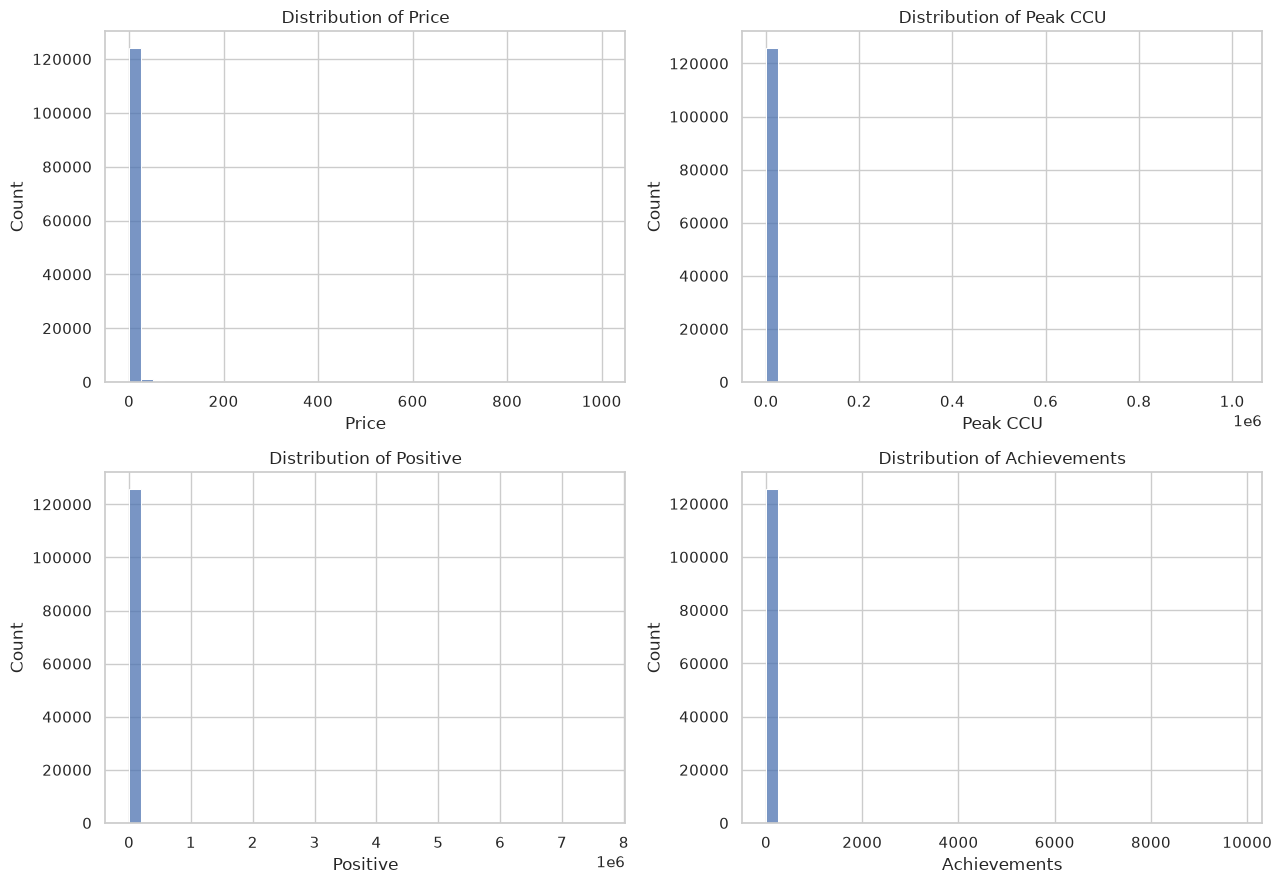

In [13]:
# Visualize distributions of selected numerical variables

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

features = [
    "Price",
    "Peak CCU",
    "Positive",
    "Achievements"
]

for ax, column in zip(axes.flat, features):
    sns.histplot(
        df[column].dropna(),
        bins=40,
        ax=ax
    )
    ax.set_title(f"Distribution of {column}")
    ax.set_xlabel(column)

plt.tight_layout()
plt.show()

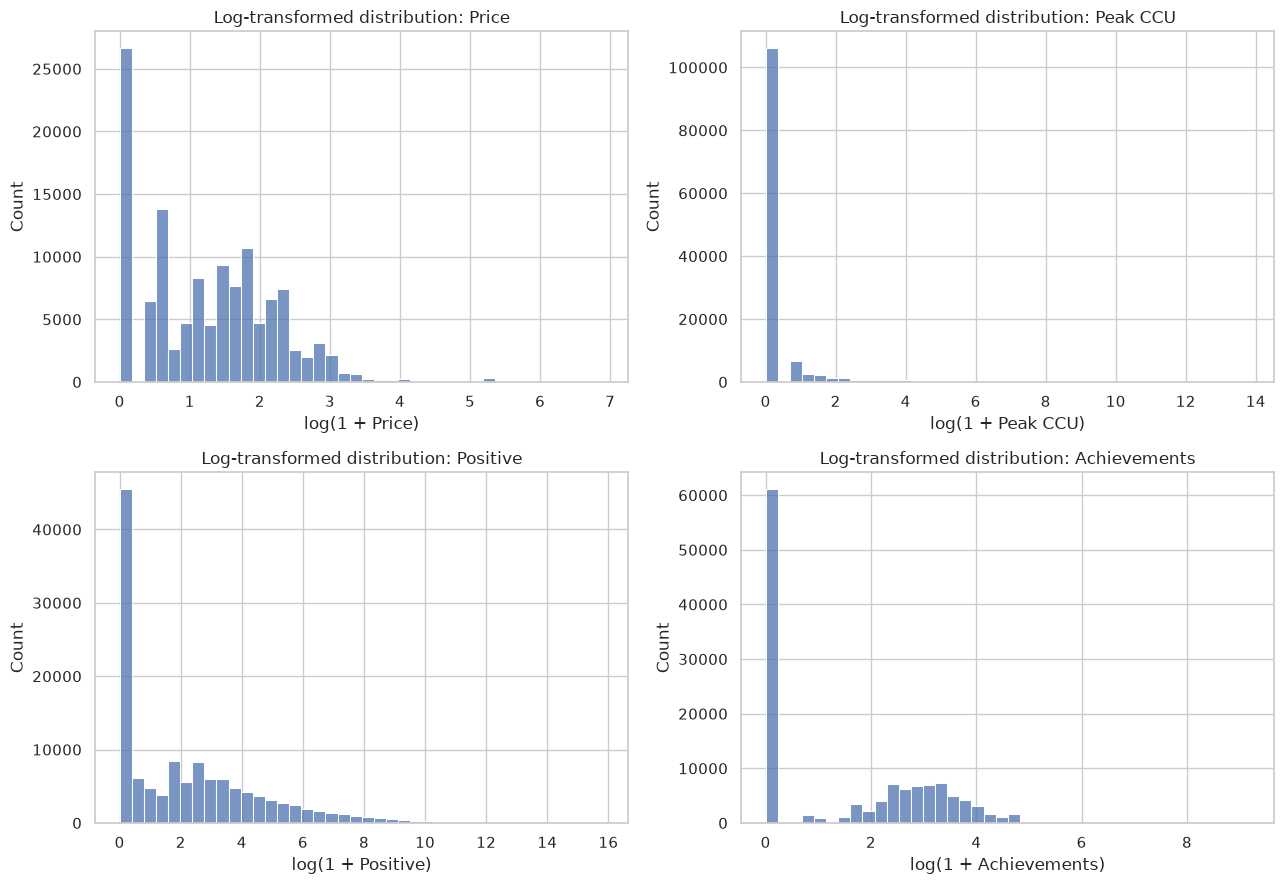

In [14]:
# Log-transformed distributions

features = [
    "Price",
    "Peak CCU",
    "Positive",
    "Achievements"
]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, column in zip(axes.flat, features):
    values = df[column].dropna()

    sns.histplot(
        np.log1p(values),
        bins=40,
        ax=ax
    )

    ax.set_title(f"Log-transformed distribution: {column}")
    ax.set_xlabel(f"log(1 + {column})")
    ax.set_ylabel("Count")

plt.tight_layout()
plt.show()

In [15]:
display(
    df[numeric_features]
    .describe(percentiles=[0.25, 0.5, 0.75, 0.90, 0.95, 0.99])
    .T
    .round(2)
)

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
Price,125855.0,4.81,12.49,0.0,0.59,2.39,5.54,9.99,14.99,29.99,999.98
Peak CCU,125855.0,53.19,3681.08,0.0,0.0,0.0,0.0,2.0,8.0,215.46,1013936.0
Positive,125855.0,1018.18,27727.82,0.0,0.0,4.0,35.0,276.0,1031.3,12869.52,7642084.0
Negative,125855.0,164.88,5305.0,0.0,0.0,1.0,10.0,68.0,215.0,2068.0,1173003.0
Recommendations,125855.0,938.04,21595.85,0.0,0.0,0.0,0.0,290.0,1022.0,12066.68,4830455.0
Achievements,125855.0,17.92,139.7,0.0,0.0,2.0,19.0,38.0,55.0,100.0,9821.0
Average playtime forever,125855.0,202.76,11072.22,0.0,0.0,0.0,0.0,227.0,479.0,2221.0,3429544.0
Average playtime two weeks,125855.0,13.51,266.93,0.0,0.0,0.0,0.0,0.0,0.0,261.0,20088.0


### 5.2 Описательная статистика — Результаты

Описательная статистика выявляет значительные различия между средними и медианными значениями нескольких числовых переменных.

Медианная цена составляет 2,39 по сравнению со средним значением 4,81. Медианное значение показателя `Peak CCU` равно нулю, что указывает на то, что как минимум половина игр не имеет зарегистрированных данных об одновременном количестве пользователей.

Количество положительных и отрицательных отзывов также имеет сильно асимметричное распределение: небольшое количество игр обладает исключительно большим числом отзывов.

Аналогичная закономерность наблюдается для достижений (`Achievements`): медианное значение составляет 2, а максимальное — 9 821.

**Вывод:** Набор данных содержит числовые переменные с выраженной правосторонней асимметрией и экстремальными значениями. Медиана и статистические показатели, основанные на процентилях, обеспечивают более репрезентативное описание типичных записей.

## 6. Выявление выбросов

В этом разделе исследуются экстремальные числовые значения с использованием метода межквартильного размаха (IQR).

Выбросы — это наблюдения, значения которых выходят за пределы статистических границ, определяемых первым и третьим квартилями.

Анализ сосредоточен на цене, активности игроков, количестве отзывов и достижениях.

Выбросы выявляются для дальнейшего исследования, а не для автоматического удаления, поскольку экстремальные значения могут представлять собой корректные наблюдения.

In [16]:
# Detect outliers using the IQR method

outlier_features = [
    "Price",
    "Peak CCU",
    "Positive",
    "Negative",
    "Achievements"
]

outlier_results = []

for column in outlier_features:
    values = df[column].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = values[(values < lower) | (values > upper)]

    outlier_results.append({
        "Column": column,
        "Lower bound": lower,
        "Upper bound": upper,
        "Outlier count": len(outliers),
        "Outlier percentage": len(outliers) / len(values) * 100
    })

outlier_table = pd.DataFrame(outlier_results)

display(outlier_table.round(2))

,Column,Lower bound,Upper bound,Outlier count,Outlier percentage
0,Price,-6.84,12.98,9256,7.35
1,Peak CCU,0.00,0.00,19680,15.64
2,Positive,-52.50,87.50,21288,16.91
3,Negative,-15.00,25.00,20700,16.45
4,Achievements,-28.50,47.50,8606,6.84


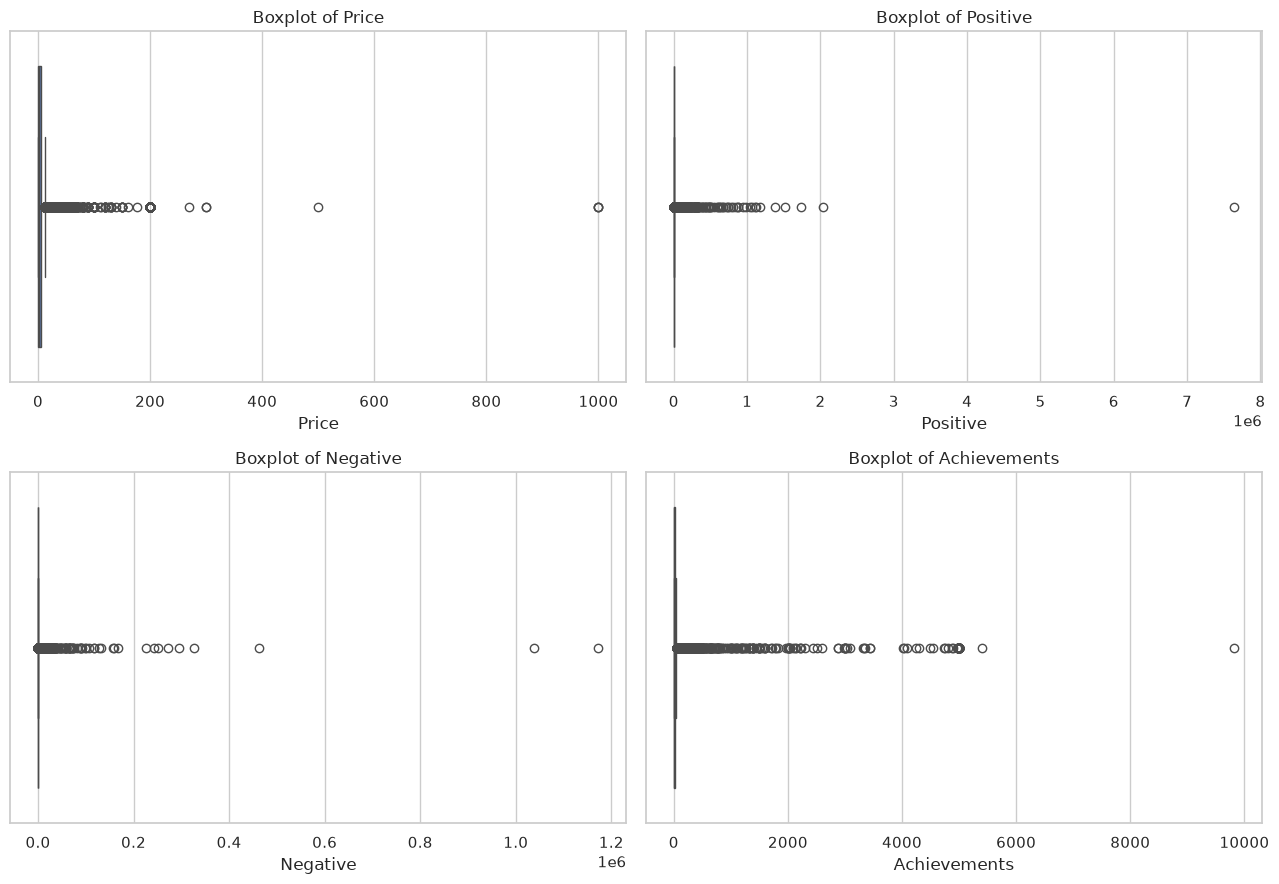

In [17]:
# Boxplots of numerical variables

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

features = [
    "Price",
    "Positive",
    "Negative",
    "Achievements"
]

for ax, column in zip(axes.flat, features):
    sns.boxplot(x=df[column], ax=ax)
    ax.set_title(f"Boxplot of {column}")

plt.tight_layout()
plt.show()

In [18]:
# Inspect the 10 highest values in selected columns

for column in [
    "Price",
    "Peak CCU",
    "Positive",
    "Achievements"
]:
    print(f"\nTop 10 values: {column}")

    display(
        df.nlargest(10, column)[
            ["Name", column, "AppID"]
        ]
    )


Top 10 values: Price


,Name,Price,AppID
41088,The Leverage Game Business Edition,999.98,2504210
68275,The Leverage Game,999.98,2499620
34463,Ascent Free-Roaming VR Experience,999.0,1200520
31935,True Love,500.0,3013840
77652,Aartform Curvy 3D 4.0,299.99,1105450
85479,Aartform Curvy 3D 3.0,299.9,253670
102212,Houdini Indie,269.99,502570
331,Hidden Industries Top-Down 3D,199.99,2023640
2035,Knights Shadow,199.99,3190870
2476,眼睛（眼球）结构研究,199.99,1035340



Top 10 values: Peak CCU


,Name,Peak CCU,AppID
45509,Counter-Strike 2,1013936,730
4193,Dota 2,623941,570
8878,PUBG: BATTLEGROUNDS,314682,578080
104347,Bongo Cat,164168,3419430
17581,ELDEN RING NIGHTREIGN,163599,2622380
5377,Rust,143870,252490
54502,Apex Legends™,124262,1172470
109015,Marvel Rivals,106611,2767030
86168,Wallpaper Engine,91184,431960
15313,DELTARUNE,83936,1671210



Top 10 values: Positive


,Name,Positive,AppID
45509,Counter-Strike 2,7642084,730
4193,Dota 2,2037143,570
59122,Grand Theft Auto V Legacy,1739980,271590
8878,PUBG: BATTLEGROUNDS,1520457,578080
10927,Terraria,1373979,105600
40969,Tom Clancy's Rainbow Six® Siege X,1172854,359550
35440,Garry's Mod,1122546,4000
44134,Black Myth: Wukong,1111720,2358720
5377,Rust,1071135,252490
57377,Team Fortress 2,1044264,440



Top 10 values: Achievements


,Name,Achievements,AppID
76082,LOGistICAL,9821,573060
8313,Drive-By Hero,5394,640310
1241,Trivia Vault: Classic Rock Trivia 2,5000,693890
5600,Trivia Vault Baseball Trivia,5000,805360
5764,Zaccaria Pinball,5000,444930
8857,Ninja Stealth 2,5000,585830
10079,Trivia Vault: Science & History Trivia,5000,687480
11008,Professor Watts Memory Match: Shapes And Colors,5000,679530
14409,Achievement Idler: Black,5000,684050
16254,Trivia Vault: Science & History Trivia 2,5000,699590


### 6.1 Анализ выбросов — Результаты

Метод межквартильного размаха (IQR) выявил потенциальные выбросы во всех пяти числовых переменных.

В столбце `Price` обнаружено 9 256 потенциальных выбросов (7,35%). Некоторые игры имеют необычно высокие цены по сравнению с общим распределением.

Для показателя `Peak CCU` выявлено 19 680 наблюдений, классифицированных как выбросы (15,64%). Однако его межквартильный размах равен нулю, поскольку как минимум 75% записей имеют нулевое зарегистрированное количество одновременных пользователей. Поэтому метод IQR не является особенно информативным для этой переменной.

Количество отзывов также содержит множество экстремальных значений. Проверка наибольших значений показывает, что многие из них относятся к известным играм с многочисленными игровыми сообществами.

Для показателя `Achievements` наблюдается аналогичная закономерность: максимальное значение составляет 9 821.

**Вывод:** Набор данных содержит значительное количество статистических выбросов, однако исследованные наблюдения не обязательно указывают на ошибки в данных. Некоторые из них отражают реальные различия между играми. Экстремальные значения следует исследовать, а не удалять.

In [19]:
# Check for impossible or suspicious numerical values

quality_checks = {
    "Negative prices": (df["Price"] < 0).sum(),
    "Negative peak CCU": (df["Peak CCU"] < 0).sum(),
    "Negative positive reviews": (df["Positive"] < 0).sum(),
    "Negative negative reviews": (df["Negative"] < 0).sum(),
    "Negative achievements": (df["Achievements"] < 0).sum(),
    "Games with no name": df["Name"].isna().sum(),
    "Games with zero AppID": (df["AppID"] == 0).sum()
}

display(pd.Series(quality_checks, name="Count").to_frame())

,Count
Negative prices,0
Negative peak CCU,0
Negative positive reviews,0
Negative negative reviews,0
Negative achievements,0
Games with no name,1
Games with zero AppID,0


In [20]:
missing_name = df[df["Name"].isna()]

display(missing_name.T)

,44432
AppID,396420
Name,<NA>
Release date,2016-11-01 00:00:00
Estimated owners,0 - 0
Peak CCU,0
Required age,0
Price,0.0
Discount,0
DLC count,0
About the game,Spookeningは3Dの恐怖ゲームで、あなたは毎夜に死んでゴーストとして復活します。 村...


**Исследование отсутствующего названия игры**

В одной записи (AppID: 396420) было обнаружено отсутствующее название игры. Однако запись содержит другую информацию, включая дату выпуска, цену, доступность на платформах и описание игры на японском языке.

Это указывает на неполноту метаданных, а не на полностью пустую запись.

**Решение:** Запись будет сохранена, а отсутствующее название останется без изменений, чтобы избежать добавления неподтверждённой информации.

In [21]:
# Examine the most common game genres

genre_counts = (
    df["Genres"]
    .dropna()
    .str.split(",")
    .explode()
    .str.strip()
    .value_counts()
)

print("Number of unique genres:", genre_counts.count())

display(genre_counts.head(15))

Number of unique genres: 33


Genres
Indie                    82884
Casual                   51677
Action                   47344
Adventure                46293
Simulation               24912
Strategy                 23058
RPG                      21577
Free To Play             12605
Early Access             11572
Sports                    4971
Racing                    4169
Massively Multiplayer     2596
Utilities                 1091
Design & Illustration      584
Animation & Modeling       484
Name: count, dtype: int64

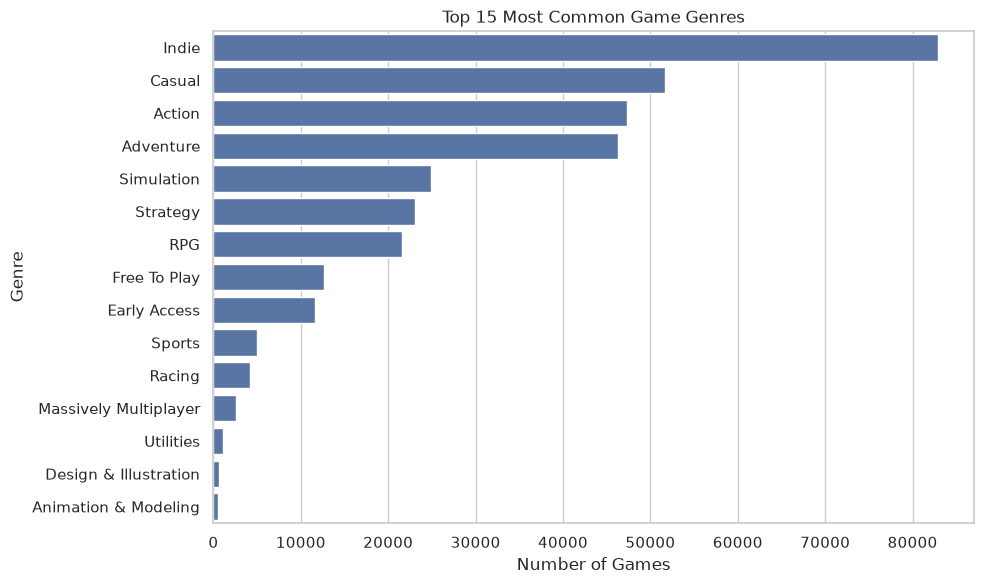

In [22]:
# Visualize the 15 most common genres

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.barplot(
    x=genre_counts.head(15).values,
    y=genre_counts.head(15).index
)

plt.title("Top 15 Most Common Game Genres")
plt.xlabel("Number of Games")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

**Распределение по жанрам — Результаты**

Набор данных содержит 33 уникальных жанра. Жанр Indie встречается наиболее часто, за ним следуют Casual, Action и Adventure.

Распределение неравномерное: небольшое количество жанров представлено значительно чаще, чем остальные. Поскольку одна игра может иметь несколько жанровых меток, подсчёты не являются взаимоисключающими.

В ходе первоначальной проверки явных структурных проблем в названиях жанров обнаружено не было.

In [23]:
# Examine the most common game categories

category_counts = (
    df["Categories"]
    .dropna()
    .str.split(",")
    .explode()
    .str.strip()
    .value_counts()
)

print("Number of unique categories:", category_counts.count())

display(category_counts.head(15))

Number of unique categories: 58


Categories
Single-player                   111078
Family Sharing                   98697
Steam Achievements               57315
Steam Cloud                      31297
Full controller support          26101
Multi-player                     20776
Partial Controller Support       13909
PvP                              12885
Steam Trading Cards              11403
Co-op                            11301
Steam Leaderboards                9411
Online PvP                        9138
Remote Play Together              7879
Custom Volume Controls            7674
Playable without Timed Input      7636
Name: count, dtype: int64

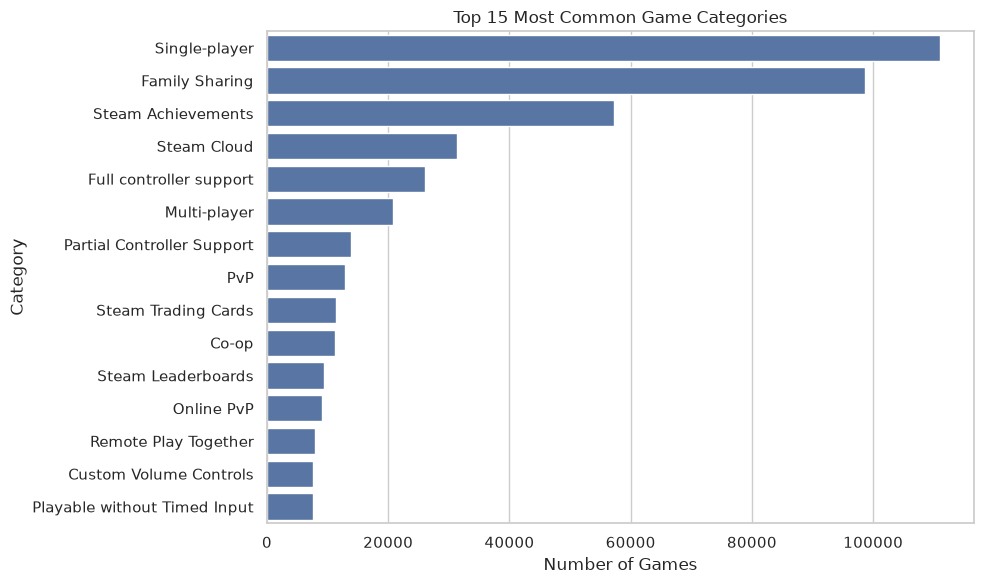

In [24]:
# Visualize the 15 most common game categories

plt.figure(figsize=(10, 6))

sns.barplot(
    x=category_counts.head(15).values,
    y=category_counts.head(15).index
)

plt.title("Top 15 Most Common Game Categories")
plt.xlabel("Number of Games")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

### Распределение по категориям — Результаты

Набор данных содержит 58 уникальных категорий. Наиболее часто встречается категория Single-player, за ней следуют Family Sharing и Steam Achievements.

Категории отражают различные игровые функции и возможности, а не исключительно жанры игрового процесса.

Распределение неравномерное: некоторые функции встречаются в значительной части игр, в то время как другие относительно редки.

In [25]:
# Analyze developers

developer_counts = (
    df["Developers"]
    .dropna()
    .str.split(",")
    .explode()
    .str.strip()
)

developer_counts = developer_counts[developer_counts != ""].value_counts()

print("Unique developers:", developer_counts.count())
display(developer_counts.head(15))

Unique developers: 77574


Developers
Inc.                        615
LLC                         495
Ltd.                        455
EroticGamesClub             232
LTD.                        227
Choice of Games             180
Boogygames Studios          157
Ltd                         156
Laush Dmitriy Sergeevich    152
Bully Revenge Studios       149
Creobit                     145
Gamesforgames               133
Tero Lunkka                 130
Cyber Keks                  125
KOEI TECMO GAMES CO.        120
Name: count, dtype: int64

In [26]:
# Analyze publishers

publisher_counts = (
    df["Publishers"]
    .dropna()
    .str.split(",")
    .explode()
    .str.strip()
)

publisher_counts = publisher_counts[publisher_counts != ""].value_counts()

print("Unique publishers:", publisher_counts.count())
display(publisher_counts.head(15))

Unique publishers: 64583


Publishers
Inc.                 754
BFG Entertainment    554
LLC                  548
Ltd.                 507
8floor               268
EroticGamesClub      232
PlayWay S.A.         222
LTD.                 210
Strategy First       209
Kagura Games         200
Conglomerate 5       197
Hede                 188
HH-Games             187
Choice of Games      180
Laush Studio         172
Name: count, dtype: int64

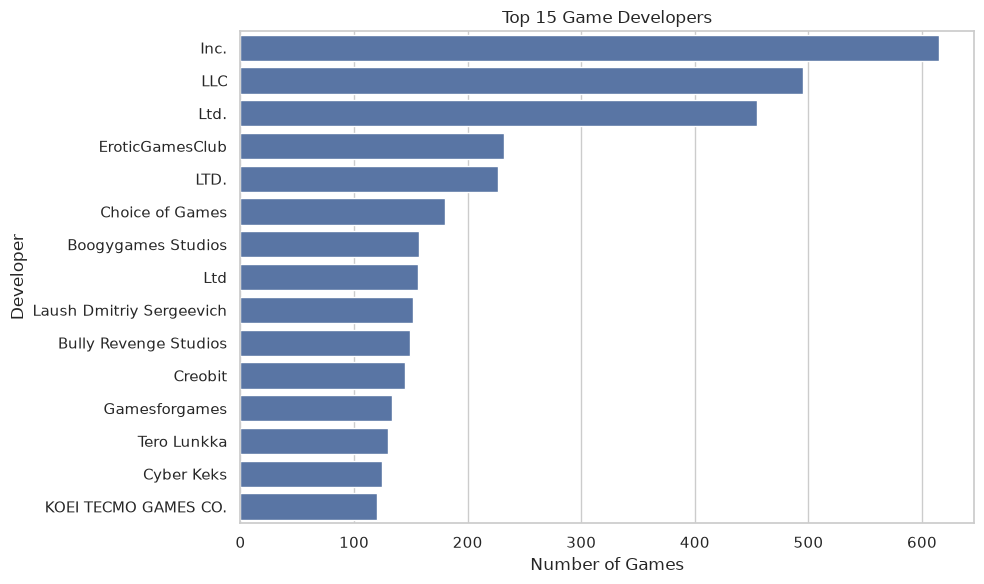

In [27]:
# Top 15 developers

plt.figure(figsize=(10, 6))
sns.barplot(
    x=developer_counts.head(15).values,
    y=developer_counts.head(15).index
)
plt.title("Top 15 Game Developers")
plt.xlabel("Number of Games")
plt.ylabel("Developer")
plt.tight_layout()
plt.show()

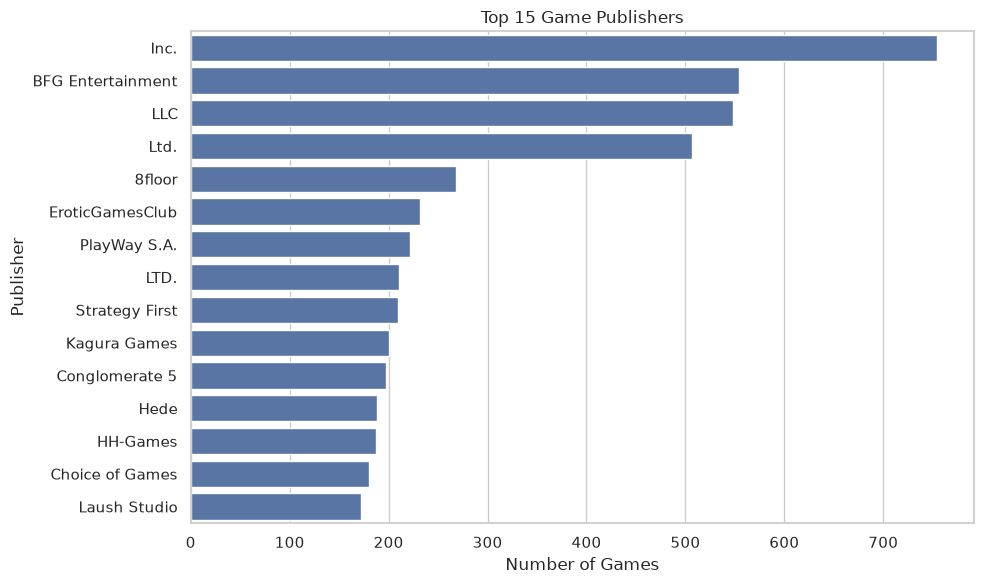

In [28]:
# Top 15 publishers

plt.figure(figsize=(10, 6))
sns.barplot(
    x=publisher_counts.head(15).values,
    y=publisher_counts.head(15).index
)
plt.title("Top 15 Game Publishers")
plt.xlabel("Number of Games")
plt.ylabel("Publisher")
plt.tight_layout()
plt.show()

In [29]:
# Inspect original developer and publisher entries

print("DEVELOPERS CONTAINING COMMAS:")
display(
    df.loc[
        df["Developers"].str.contains(",", na=False),
        ["Developers"]
    ].head(15)
)

print("\nPUBLISHERS CONTAINING COMMAS:")
display(
    df.loc[
        df["Publishers"].str.contains(",", na=False),
        ["Publishers"]
    ].head(15)
)

DEVELOPERS CONTAINING COMMAS:


,Developers
15,"Witching Hour Entertainment LLC,LarsMidnatt"
17,"Accolade, Inc."
26,"Plausible Concept,Oskar Stålberg"
30,"Gemdrops, Inc."
61,"Mix3Games,Bigos Games"
67,"Eidos-Montréal,Crystal Dynamics,Nixxes,Feral I..."
72,"Renato Gomes Marcacini,Leonardo Olivieri Carvalho"
76,"Mzg Games,Mzg Games"
81,"the last evil wizard,Nupu Neko Dev"
103,"Gravvit Ltd,Forbes Consult Ltd"



PUBLISHERS CONTAINING COMMAS:


,Publishers
5,"Ignibit,Madmind Studio"
13,"9 Eyes Game Studio,Stately Snail"
17,"Atari,Nightdive Studios"
30,"Gemdrops, Inc."
57,"First Peoples Digital,Nejcraft"
67,"Crystal Dynamics,Feral Interactive (Mac),Feral..."
72,"Anchor Games,Nato Games"
85,"Mediascape Co., Ltd."
106,"Handong Global University,BCILAB"
125,"familyplay,Markt+Technik Verlag"


In [30]:
# Split multiple names while preserving commas inside company names

developers = (
    df["Developers"]
    .dropna()
    .str.split(r",(?=\S)")
    .explode()
    .str.strip()
)

publishers = (
    df["Publishers"]
    .dropna()
    .str.split(r",(?=\S)")
    .explode()
    .str.strip()
)

# Remove empty values
developers = developers[developers != ""]
publishers = publishers[publishers != ""]

print("Top 15 Developers:")
display(developers.value_counts().head(15))

print("\nTop 15 Publishers:")
display(publishers.value_counts().head(15))

Top 15 Developers:


Developers
EroticGamesClub               232
Choice of Games               180
Boogygames Studios            157
Laush Dmitriy Sergeevich      152
Bully Revenge Studios         149
Creobit                       145
Gamesforgames                 133
Tero Lunkka                   130
Cyber Keks                    125
KOEI TECMO GAMES CO., LTD.    120
Hosted Games                  119
Sokpop Collective             112
Ltd.                          108
Ltd                           107
Do Games Limited              102
Name: count, dtype: int64


Top 15 Publishers:


Publishers
BFG Entertainment     554
8floor                268
EroticGamesClub       232
PlayWay S.A.          222
Strategy First        209
Kagura Games          200
Conglomerate 5        197
Hede                  188
HH-Games              186
Choice of Games       180
Laush Studio          172
Sekai Project         168
THQ Nordic            167
Plug In Digital       161
Boogygames Studios    157
Name: count, dtype: int64

In [31]:
# Investigate remaining company suffix entries

for name in ["Ltd.", "Ltd"]:
    print(f"\nOriginal developer entries containing {name}:")
    display(
        df.loc[
            developers[
                developers.str.fullmatch(name, case=False, na=False)
            ].index,
            ["Developers"]
        ].head(10)
    )


Original developer entries containing Ltd.:


,Developers
1560,"Sologram Co.,Ltd."
1877,"TOM CREATE CO.,LTD."
2944,"PRIME WORKS Co.,Ltd."
4513,"USERJOY Technology Co.,Ltd."
6374,"IMCGAMES Co.,Ltd."
6881,"TOM CREATE CO.,LTD."
7420,"Hit-Point Co.,Ltd."
7819,"USERJOY Technology Co.,Ltd."
8004,"Orbital Speed Studio Co.,Ltd."
8135,"ZuoYuanYouYang Co.,Ltd."



Original developer entries containing Ltd:


,Developers
1258,"CHENGDU DREAMCALLER TECHNOLOGY CO.,LTD"
4889,"Kairosoft Co.,Ltd"
6262,"Kairosoft Co.,Ltd"
6389,"Kairosoft Co.,Ltd"
8074,"SE.EED CO.,LTD"
8235,"BeiJing FlyDream Interactive co.,ltd"
8697,"Shanghai ThinkingBear Network Technology Co.,Ltd"
11447,"M2 Co.,LTD"
11570,"Kairosoft Co.,Ltd"
12108,"Kairosoft Co.,Ltd"


In [32]:
# Split multiple names while preserving company suffixes

separator = r",(?=\S)(?![Ll][Tt][Dd]\.?(?:$|,))"

developers = (
    df["Developers"]
    .dropna()
    .str.split(separator, regex=True)
    .explode()
    .str.strip()
)

publishers = (
    df["Publishers"]
    .dropna()
    .str.split(separator, regex=True)
    .explode()
    .str.strip()
)

developers = developers[developers != ""]
publishers = publishers[publishers != ""]

print("Top 15 Developers:")
display(developers.value_counts().head(15))

print("\nTop 15 Publishers:")
display(publishers.value_counts().head(15))

Top 15 Developers:


Developers
EroticGamesClub               232
Choice of Games               180
Boogygames Studios            157
Laush Dmitriy Sergeevich      152
Bully Revenge Studios         149
Creobit                       145
Gamesforgames                 133
Tero Lunkka                   130
Cyber Keks                    125
KOEI TECMO GAMES CO., LTD.    120
Hosted Games                  119
Sokpop Collective             112
Do Games Limited              102
Hede                          102
King Kong                     101
Name: count, dtype: int64


Top 15 Publishers:


Publishers
BFG Entertainment     554
8floor                268
EroticGamesClub       232
PlayWay S.A.          222
Strategy First        209
Kagura Games          200
Conglomerate 5        197
Hede                  188
HH-Games              186
Choice of Games       180
Laush Studio          172
Sekai Project         168
THQ Nordic            167
Plug In Digital       161
Boogygames Studios    157
Name: count, dtype: int64

### Анализ разработчиков и издателей

Названия разработчиков и издателей были извлечены из набора данных и подсчитаны для определения компаний, встречающихся наиболее часто.

В процессе предварительной обработки особого внимания потребовали имена, разделённые запятыми, поскольку запятые также могут входить в состав названий компаний (например, `Co., Ltd.`). Для сохранения распространённых окончаний названий компаний и уменьшения количества ошибочных разделений было применено специальное правило разделения.

Результаты показывают, что некоторые разработчики и издатели представлены в нескольких играх. Однако различия в написании названий и непоследовательное форматирование всё ещё могут влиять на результаты подсчётов.

## 7. Корреляционный анализ

Корреляционный анализ используется для изучения взаимосвязей между числовыми переменными. Выбран коэффициент корреляции Спирмена, поскольку несколько переменных имеют сильно асимметричные распределения и экстремальные значения.

In [33]:
# Select relevant numerical variables

correlation_columns = [
    "Price",
    "Peak CCU",
    "Positive",
    "Negative",
    "Recommendations",
    "Achievements",
    "Average playtime forever",
    "Average playtime two weeks"
]

# Calculate Spearman correlation
correlation_matrix = df[correlation_columns].corr(
    method="spearman"
)

display(correlation_matrix.round(2))

,Price,Peak CCU,Positive,Negative,Recommendations,Achievements,Average playtime forever,Average playtime two weeks
Price,1.00,0.20,0.20,0.16,0.24,0.20,0.19,0.13
Peak CCU,0.20,1.00,0.52,0.50,0.61,0.25,0.58,0.38
Positive,0.20,0.52,1.00,0.87,0.53,0.31,0.59,0.23
Negative,0.16,0.50,0.87,1.00,0.53,0.25,0.61,0.23
Recommendations,0.24,0.61,0.53,0.53,1.00,0.32,0.73,0.41
Achievements,0.20,0.25,0.31,0.25,0.32,1.00,0.30,0.17
Average playtime forever,0.19,0.58,0.59,0.61,0.73,0.30,1.00,0.39
Average playtime two weeks,0.13,0.38,0.23,0.23,0.41,0.17,0.39,1.00


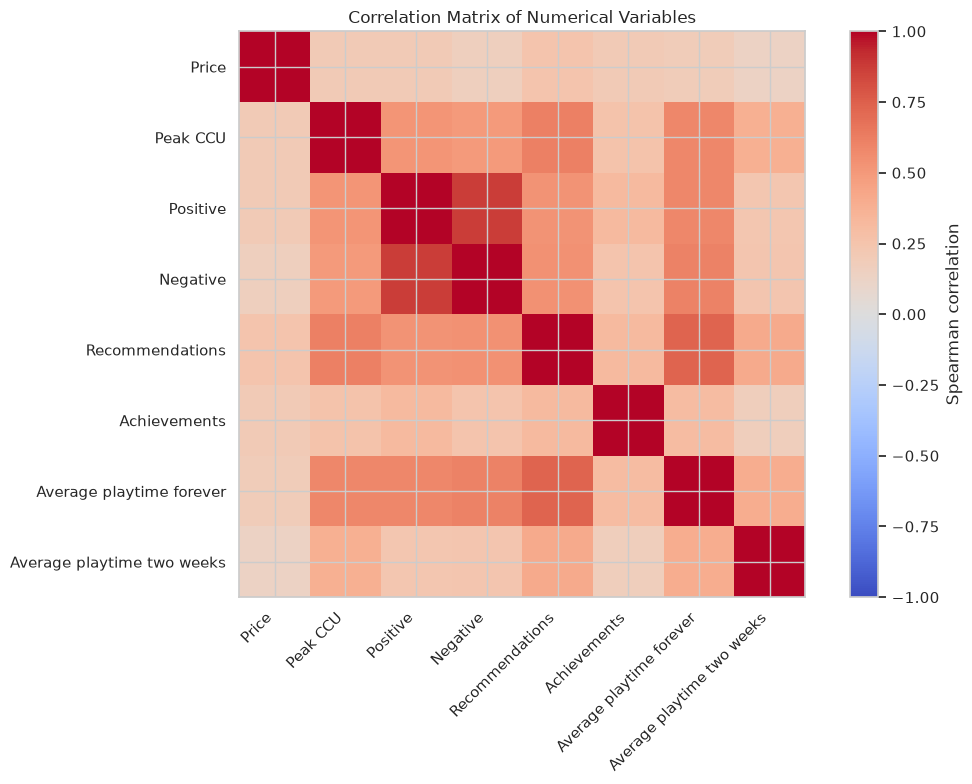

In [34]:
plt.figure(figsize=(11, 8))

plt.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Spearman correlation")

plt.xticks(
    range(len(correlation_columns)),
    correlation_columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation_columns)),
    correlation_columns
)

plt.title("Correlation Matrix of Numerical Variables")
plt.tight_layout()
plt.show()

In [35]:
# Extract the strongest correlations (excluding self-correlations)

correlation_pairs = (
    correlation_matrix
    .where(
        ~np.eye(correlation_matrix.shape[0], dtype=bool)
    )
    .stack()
    .sort_values(ascending=False)
)

# Remove duplicate pairs
correlation_pairs = correlation_pairs[
    correlation_pairs.index.map(
        lambda x: x[0] < x[1]
    )
]

display(correlation_pairs.head(10).to_frame("Spearman correlation"))

Spearman correlation
Negative                 Positive                     0.870637
Average playtime forever Recommendations              0.734356
Peak CCU                 Recommendations              0.614533
Average playtime forever Negative                     0.605703
                         Positive                     0.585147
                         Peak CCU                     0.582525
Negative                 Recommendations              0.531254
Positive                 Recommendations              0.531194
Peak CCU                 Positive                     0.516912
Negative                 Peak CCU                     0.496329

### Корреляционный анализ — Результаты

Корреляционный анализ выявил несколько положительных взаимосвязей между игровой активностью и показателями вовлечённости игроков.

Количество положительных и отрицательных отзывов показало сильную положительную корреляцию, что свидетельствует о том, что игры, получающие больше отзывов, как правило, накапливают как положительные, так и отрицательные отзывы.

Показатели `Peak CCU`, `Recommendations` и `Lifetime playtime` также продемонстрировали положительные взаимосвязи, указывая на связь между активностью игроков и накопленной вовлечённостью.

Цена показала относительно слабую корреляцию с большинством переменных, в то время как достижения (`Achievements`) в целом имели более слабые взаимосвязи с выбранными показателями.

В целом результаты показывают, что показатели вовлечённости игроков теснее связаны друг с другом, чем с ценой игры. Эти корреляции описывают взаимосвязи и не подразумевают причинно-следственную зависимость.

### Корреляционный анализ — Результаты

Наиболее сильная корреляция наблюдалась между количеством положительных и отрицательных отзывов (ρ = 0,871). Это свидетельствует о том, что игры, получающие больше положительных отзывов, как правило, также накапливают больше отрицательных отзывов, что, вероятно, связано с общим количеством отзывов.

Показатель `Lifetime playtime` продемонстрировал сильную положительную корреляцию с количеством рекомендаций (`Recommendations`) (ρ = 0,734). Показатель `Peak CCU` также положительно коррелировал с количеством рекомендаций (ρ = 0,615).

Другие умеренные положительные взаимосвязи наблюдались между `Lifetime playtime`, `Peak CCU` и количеством отзывов.

В целом показатели вовлечённости игроков продемонстрировали более сильные взаимосвязи друг с другом, чем с другими числовыми переменными. Эти результаты отражают статистические взаимосвязи и не устанавливают причинно-следственную зависимость.

# 8. Итоговые выводы

## Обзор набора данных

Анализ охватил 125 855 записей и 40 столбцов набора данных об играх Steam.

Набор данных содержит информацию о характеристиках игр, ценах, активности игроков, отзывах, разработчиках, издателях и поддерживаемых платформах.

## Результаты оценки качества данных

Было выявлено несколько проблем с качеством данных:

- **Пропущенные значения:** Некоторые столбцы содержат значительное количество пропущенных данных. Столбец Movies полностью пуст, а значения в столбце Score rank отсутствуют почти во всех записях.
- **Дубликаты:** Дублирующиеся строки и повторяющиеся значения AppID не обнаружены.
- **Отсутствующие идентификаторы:** В одной записи отсутствует название игры.
- **Нулевые значения:** Несколько числовых столбцов содержат высокую долю нулевых значений, особенно User score, Required age и показатели игрового времени.
- **Выбросы:** Несколько числовых переменных имеют сильно асимметричные распределения и экстремальные значения, особенно показатели активности игроков и количества отзывов.
- **Форматирование данных:** Названия разработчиков и издателей требуют тщательной обработки, поскольку названия компаний и несколько записей могут содержать запятые.

## Статистические результаты

Числовой анализ выявил сильно асимметричные распределения нескольких переменных.

Наиболее сильная корреляция Спирмена наблюдалась между количеством положительных и отрицательных отзывов (ρ = 0,871). Показатели Lifetime playtime и Recommendations также продемонстрировали сильную положительную взаимосвязь (ρ = 0,734).

Жанры игр распределены неравномерно, при этом Indie и Casual являются наиболее часто встречающимися жанрами.

## Ограничения

Некоторые пропущенные значения могут отражать отсутствие доступной информации, а не ошибки. Аналогичным образом, нулевые значения нельзя автоматически интерпретировать как пропущенные данные.

Экстремальные значения были выявлены, но не удалены, поскольку они могут представлять собой корректные наблюдения.

Извлечение названий разработчиков и издателей также основано на эвристическом правиле разделения и может сохранять некоторые несоответствия.

## Итоговая оценка

Набор данных предоставляет обширную информацию об играх Steam, однако его полнота и согласованность значительно различаются между столбцами.

Основными проблемами качества данных являются отсутствие информации, сильно асимметричные числовые переменные, непоследовательное текстовое форматирование и потенциально неоднозначные нулевые значения.

Проведённый анализ даёт общее представление об этих ограничениях без изменения или удаления потенциально корректных наблюдений.

In [36]:
print("Earliest release date:", df["Release date"].min())
print("Latest release date:", df["Release date"].max())
print("Missing release dates:", df["Release date"].isna().sum())

Earliest release date: 1997-06-30 00:00:00
Latest release date: 2026-12-01 00:00:00
Missing release dates: 0


In [37]:
platform_columns = ["Windows", "Mac", "Linux"]

display(
    df[platform_columns]
    .apply(lambda col: col.value_counts(dropna=False))
)

,Windows,Mac,Linux
False,44,104136,109786
True,125811,21719,16069


In [38]:
review_check = df[
    ["Positive", "Negative"]
].copy()

review_check["Total reviews"] = (
    review_check["Positive"] + review_check["Negative"]
)

display(review_check.describe().round(2))

,Positive,Negative,Total reviews
count,125855.0,125855.0,125855.0
mean,1018.18,164.88,1183.06
std,27727.82,5305.0,32214.01
min,0.0,0.0,0.0
25%,0.0,0.0,0.0
50%,4.0,1.0,6.0
75%,35.0,10.0,46.0
max,7642084.0,1173003.0,8815087.0


In [39]:
# Identify games with future release dates

future_games = df[
    df["Release date"] > pd.Timestamp.today().normalize()
]

print("Games with future release dates:", len(future_games))

display(
    future_games[
        ["AppID", "Name", "Release date"]
    ].head(15)
)

Games with future release dates: 1


,AppID,Name,Release date
125386,4418940,Roten,2026-12-01


- **Будущие даты выпуска:** У одной игры (Roten) указана дата выпуска 1 декабря 2026 года, которая наступает позже даты проведения анализа. Это может указывать на реальный предстоящий релиз, а не на ошибочную дату.